<a class="anchor" id="0"></a>
# **Mubileum Duration Generation with VAE**

<a class="anchor" id="0.1"></a>
# **Table of Contents**

- 1. [Setup](#1)
- 2. [Data Preparation](#2)
<!--     - 2.1 [Data Preparation for LSTM](#2.1) -->
- 3. [EDA](#3)
- 4. [Anomaly Detection](#4)
- 5. [Anomaly Creation](#5)
- 6. [Genetic Algoritm Otimization](#6)


# **1. SetUp** <a class="anchor" id="1"></a>

[Table of Contents](#0.1)

In [1]:
# Data Manipulation and Analysis
import numpy as np
import pandas as pd
from tqdm import tqdm 
import random

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn for Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve


# Read a CSV file into a Pandas DataFrame
df = pd.read_csv("/kaggle/input/mobileum/jul_aug_sep_oct_2022_msc_1.csv", sep=";")

# Convert Start Date and Start Hour into a datetime object and set as index
df['TIMESTAMP'] = pd.to_datetime(df['Start Date'] + ' ' + df['Start Hour'].astype(str), format='%d/%m/%Y %H')
# df.set_index("TIMESTAMP", inplace=True)

# Clean the #Events column, remove any non-numeric characters, fill NaNs with 0, and convert to integer
df['#Events'] = df['#Events'].str.replace(r'[^\d.-]', '', regex=True)
df['#Events'] = df['#Events'].fillna(0)
df['#Events'] = pd.to_numeric(df['#Events']).astype(int)

# Drop unnecessary columns
# df.drop(columns=['Datasource', 'Start Date', 'Start Hour'], inplace=True) 
df.drop(columns=['Datasource', 'Start Date', 'Start Hour', 'Event Duration'], inplace=True)

# Drop duplicates
df.drop_duplicates(inplace=True)
# df=df.reset_index()

In [2]:
filters = pd.read_csv("/kaggle/input/mobileum-empty-agg/not_empty_combinations.csv")

In [3]:
def contain_condition(df, conditions):
    if not conditions:
        return False
    pd_conditions = " & ".join([f'`{key}` == "{value}"' for key, value in conditions.items()])
    return df.eval(pd_conditions).any()

# **4. Anomaly Creation** <a class="anchor" id="4"></a>

[Table of Contents](#0.1)

In [4]:
def filter_and_aggregate(df, filter_conditions, hierarchy=False):
    """
    Filters the DataFrame based on given conditions and aggregates by summing up a specified column.
    
    Args:
    - df: The original DataFrame.
    - filter_conditions: A dictionary where keys are column names and values are the values to filter on.
    
    Returns:
    - A new DataFrame with the filtered and aggregated data.
    """
    # Apply the filter conditions
    df_fil = df.copy()
    
    for col, val in filter_conditions.items():
        df_fil = df_fil[df_fil[col] == val]
    
    # Drop the columns used for filtering
    df_fil.drop(columns=list(filter_conditions.keys()), inplace=True)
    
    # Group by 'TIMESTAMP' and sum up the '#Events' column
    if hierarchy:
        df_agg = df_fil.groupby('TIMESTAMP')[['#Events','Anomaly']].sum().reset_index()
    else:
        df_agg = df_fil.groupby('TIMESTAMP')['#Events'].sum().reset_index()
    
    return df_agg


In [5]:
def generate_anomaly(mean, std, lower_bound=0):
    """
    Generate a random anomaly value.
    
    Parameters:
    mean (float): The mean value of the normal data.
    std (float): The standard deviation of the normal data.
    lower_bound (int): The minimum value an anomaly can take, inclusive. Default is 0.
    
    Returns:
    int: An anomalous data point.
    """
    print(mean, std)
    upper_normal = mean + 3 * std
    lower_normal = max(mean - (3 * std), lower_bound)
    
    
    # Choose between an anomaly below or above the normal range.
    anomaly_value = np.random.choice([upper_normal, lower_normal])
    return anomaly_value


In [6]:
def insert_anomaly(df, df_anomaly, index, unique_conditions, plot=False):
    # Identify time-stamp at the given index
    ts = df_anomaly.iloc[index]['TIMESTAMP']
    
    # Define window for calculating std and mean
    start = max(index - 84, 0)
    end = min(index + 83, len(df_anomaly) - 1)
    
    print(start, end)
    print(ts)
    # Calculate standard deviation and mean within the window and if the window is equal to 1
    if start != end:
        std = df_anomaly[start:end]['#Events'].std()
        mean = df_anomaly[start:end]['#Events'].mean()
        anomaly_value = generate_anomaly(mean, std)
    else:
        value = std= mean = df_anomaly.iloc[start]['#Events']

        anomaly_value = np.random.choice([max(value-value/2,0), value*3/2])
    

    
    mask = (df['TIMESTAMP'] == ts)

    # Apply additional conditions from dictionary of conditions
    for col, val in unique_conditions.items():
        mask &= (df[col] == val)

    # This mask can now be used to filter df
    rows_with_ts = df[mask]

    # Sum of '#Events' for these rows
    sum_events = rows_with_ts['#Events'].sum()

    # Calculate multiplier
    m = anomaly_value / sum_events

    # Check if the 'Anomaly' column exists
    if 'Anomaly' not in df.columns:
        df['Anomaly'] = 0
    
    print(len(df.loc[mask, '#Events']))
    print(df.loc[mask, '#Events'])
    # Apply multiplier and round to integer values
    df.loc[mask, '#Events'] = (rows_with_ts['#Events'] * m).round().astype(int)
    print(df.loc[mask, '#Events'])
    # Update 'Anomaly' column only for rows where '#Events' 
    df.loc[mask, 'Anomaly'] = 1
    
    
    if plot == True:
#         print(f"Anomaly value: {anomaly_value}")
        plt.figure(figsize=(10, 6))
        plt.plot(df_original["TIMESTAMP"], df_original["#Events"], label="Events", marker='o', linestyle='-', markersize=4)
        plt.scatter(ts, anomaly_value, color='red', s=100, label='Anomaly', zorder=5)
        plt.xlabel('TIMESTAMP')
        plt.ylabel('#Events')
        plt.title('Visualization of #Events with Anomaly Inserted')
        plt.legend()
        plt.grid(True)
        plt.show()

    
    # Print actual and anomaly values
    actual_value = df_anomaly.iloc[index]['#Events']
    anomaly_value_df = df.loc[mask, '#Events'].sum()
#     print("actual_value:", actual_value, "Anomaly_value:", anomaly_value,"Anomaly_value_df:", anomaly_value_df, "Mean:", mean, "Std:", std)
    
    return ts, mean, std, anomaly_value, anomaly_value_df, actual_value, unique_conditions

In [7]:
def insert_nanomaly(df, n_anomalies, plot=False):
    
    columns = ['Call Type', 'Event Type', 'Subscriber Type', 'Traffic Type', 'Service Type', 'Partner Description']
    
    # Store anomalies for plotting
    anomaly_records = []
    
    # Store unique conditions to ensure they are not repeated
    used_conditions = set()
    
    df_anomaly = df.copy()
    
    # Check if the 'Anomaly' column exists
    if 'Anomaly' not in df_anomaly.columns:
        df_anomaly['Anomaly'] = 0
    
    for _ in tqdm(range(n_anomalies), desc='Inserting anomalies'):
            while True:
                # Ensure that the same new_columns and unique_conditions are not generated again
                new_columns = [col for col in columns if random.random() < 0.5]
                unique_conditions = {col: random.choice(df[col].unique()) for col in new_columns}
                conditions_tuple = tuple(sorted(unique_conditions.items()))  # Need to convert to a hashable type to store in a set

                if conditions_tuple not in used_conditions:
                    

                    # Retry if df_fil is empty, otherwise, break the loop
                    if contain_condition(filters, unique_conditions):
                        df_fil = filter_and_aggregate(df, unique_conditions)
                        used_conditions.add(conditions_tuple)
                        index = random.choice(df_fil.index)
                        ts, mean, std, anomaly_value, anomaly_value_df, actual_value, conditions = insert_anomaly(df_anomaly, df_fil, index, unique_conditions, plot=False)
                        anomaly_records.append((ts, mean, std, anomaly_value, anomaly_value_df, actual_value, conditions))
                        break  # Successfully inserted an anomaly, can exit loop
                    else:
                        print("This aggregation is empty, retrying with new unique conditions.")
    
    
    anomalies_info_df = pd.DataFrame(anomaly_records, columns=['TIMESTAMP', 'Mean', 'STD', 'Anomaly Value', 'Anomaly Value from DF', 'Actual Value', 'Used Conditions'])
    aux= filter_and_aggregate(df_anomaly, {}, True)
    # Merge dataframes based on timestamp
    mask = aux["TIMESTAMP"].isin(anomalies_info_df["TIMESTAMP"])
    filtered_aux = aux[mask]

    if plot:
        plt.figure(figsize=(10, 6))
        plt.plot(aux["TIMESTAMP"], aux["#Events"], label="Events", marker='o', linestyle='-', markersize=4)

        # Extract timestamps and anomaly values for plotting
#         ts_values, anomaly_values = zip(*anomaly_records) if anomaly_records else ([], [])
        plt.scatter(filtered_aux["TIMESTAMP"], filtered_aux["#Events"], color='red', s=100, label='Anomaly', zorder=5)

        plt.xlabel('TIMESTAMP')
        plt.ylabel('#Events')
        plt.title('Visualization of #Events with Anomaly Inserted')
        plt.legend()
        plt.grid(True)
        plt.show()
    
#     ?<create a dataframe which store the (ts, mean, std, anomaly_value, anomaly_value_df, actual_value and used_conditions)
    

    # Optional: print out the anomaly records for debugging
#     print(anomaly_records)
    
    return df_anomaly, anomalies_info_df


In [8]:
df.describe()

,#Events,TIMESTAMP
count,9.584800e+05,958480
mean,2.395870e+03,2022-08-31 16:35:17.711793408
min,0.000000e+00,2022-07-18 00:00:00
25%,2.000000e+00,2022-08-09 20:00:00
50%,9.000000e+00,2022-09-01 00:00:00
75%,5.900000e+01,2022-09-22 17:00:00
max,3.053227e+06,2022-10-13 21:00:00
std,3.119447e+04,NaN


1. get the anomaly_value and the ts with the function. 
2. go to the original df get all the rows with the same ts (TIMESTAMP)
3. from all the row calculate the sum of column (#Events)
4. calculate the multiplier witch m = anomaly_value/ sum of column (#Events)
5. use the multiplier to all rows of the #Events and do the round to get int
6. Create an new columns witch name "Anomaly" with 0 or 1, which all row which has column 
7. gerate an orignal and modified df

Inserting anomalies:   0%|          | 0/105 [00:00<?, ?it/s]

This aggregation is empty, retrying with new unique conditions.


Inserting anomalies:   1%|          | 1/105 [00:00<01:01,  1.69it/s]

1220 1387
2022-09-10 08:00:00
234009.09580838322 119169.0515094142
405
581440      3
581441      5
581442      9
581443     14
581444      7
         ... 
581878    147
581879      4
581880     49
581881     21
581882     99
Name: #Events, Length: 405, dtype: int64
581440      7
581441     11
581442     20
581443     32
581444     16
         ... 
581878    332
581879      9
581880    111
581881     47
581882    224
Name: #Events, Length: 405, dtype: int64


Inserting anomalies:   2%|▏         | 2/105 [00:00<00:41,  2.46it/s]

273 440
2022-08-01 21:00:00
72158.30538922155 43227.33886440087
11
154505       26
154512    20015
154513       19
154534    10074
154535       21
154750      145
154860        7
154861        1
154872       84
154921        3
154922    58404
Name: #Events, dtype: int64
154505    0
154512    0
154513    0
154534    0
154535    0
154750    0
154860    0
154861    0
154872    0
154921    0
154922    0
Name: #Events, dtype: int64


... (202 outputs left out)

Inserting anomalies:  99%|█████████▉| 104/105 [01:15<00:00,  1.62it/s]

142 309
2022-07-27 10:00:00
202.9760479041916 140.8890425633141
5
97142    151
97185     25
97348      2
97510      3
97551      7
Name: #Events, dtype: int64
97142    0
97185    0
97348    0
97510    0
97551    0
Name: #Events, dtype: int64
640 807
2022-08-17 04:00:00
9796.377245508982 5771.764798304674


Inserting anomalies: 100%|██████████| 105/105 [01:15<00:00,  1.38it/s]

1
318220    1587
Name: #Events, dtype: int64
318220    0
Name: #Events, dtype: int64


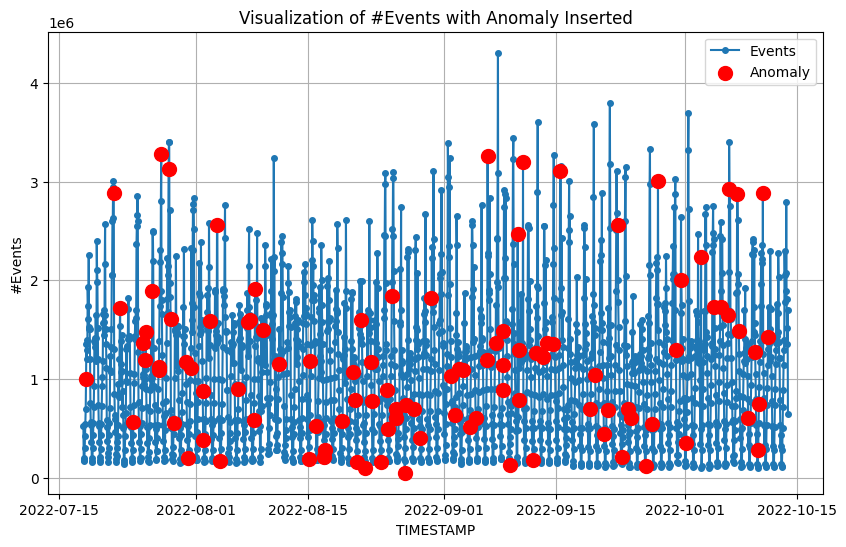

In [9]:
df_anomaly, df_info = insert_nanomaly(df, 105, plot=True)

In [10]:
df_anomaly.Anomaly.sum()

4425

In [11]:
900000 * 0.05

45000.0

In [12]:
df_anomaly.to_csv("/kaggle/working/df_anomaly.csv", index=False)

In [13]:
df_info

,TIMESTAMP,Mean,STD,Anomaly Value,Anomaly Value from DF,Actual Value,Used Conditions
0,2022-09-10 08:00:00,234009.095808,119169.051509,591516.250337,591523,261851,{'Traffic Type': 'INT'}
1,2022-08-01 21:00:00,72158.305389,43227.338864,0.000000,0,88799,{'Event Type': 'CALL FORWARD'}
2,2022-08-24 02:00:00,4093.964072,2066.479431,0.000000,0,744,"{'Call Type': 'VOICE', 'Subscriber Type': 'Roa..."
3,2022-10-06 11:00:00,94760.401198,61335.916119,0.000000,0,183307,"{'Call Type': 'VOICE', 'Subscriber Type': 'Pos..."
4,2022-08-07 12:00:00,45874.910180,32270.480622,142686.352045,142686,57631,"{'Call Type': 'SMS', 'Subscriber Type': 'Postp..."
...,...,...,...,...,...,...,...
100,2022-07-27 09:00:00,79092.904192,47411.075440,221326.130513,221326,127617,"{'Call Type': 'VOICE', 'Subscriber Type': 'Pos..."
101,2022-10-10 04:00:00,17.680000,23.986663,89.639989,90,14,"{'Event Type': 'TERMINATED', 'Service Type': '..."
102,2022-10-07 14:00:00,266.125749,558.001988,0.000000,0,615,"{'Call Type': 'VOICE', 'Subscriber Type': 'App..."
103,2022-07-27 10:00:00,202.976048,140.889043,0.000000,0,188,{'Partner Description': 'P_0092'}


In [14]:
size = len(df[df["#Events"] != df_anomaly["#Events"]])
print(f"Size of number o anomalies inserted into desaggregated df: {size}")

Size of number o anomalies inserted into desaggregated df: 4288


## Number of examples (rows) on aggreagated with all features with return not an empty dataframe

In [15]:
row_plus_two = len(filters[filters["Number of examples (rows)"]>2])
row_equal_two = len(filters[filters["Number of examples (rows)"]==2])
row_one = len(filters[filters["Number of examples (rows)"]==1])

print(f"Dataframe with more than 2 rows: {row_plus_two}\nDataframe with 2 rows: {row_equal_two}\nDataframe with one row: {row_one} ")

Dataframe with more than 2 rows: 1374
Dataframe with 2 rows: 54
Dataframe with one row: 127 


### Selecting one df_anomaly and analysis how this affect global and locally on the dataset

In [16]:
index = np.random.choice(range(len(df_info)-1))
center_ts = df_info.iloc[index]["TIMESTAMP"]
condictions = df_info.iloc[index]["Used Conditions"]
(index, center_ts, condictions)

(67,
 Timestamp('2022-09-08 07:00:00'),
 {'Call Type': 'VOICE',
  'Subscriber Type': 'Application',
  'Traffic Type': 'OFF-NET',
  'Service Type': 'ROAMING'})

### Random select one anomaly from generated anomalies

In [17]:
index = np.random.choice(range(len(df_info)-1))
center_ts = df_info.iloc[index]["TIMESTAMP"]
conditions = df_info.iloc[index]["Used Conditions"]
static_value = list(conditions.values())[0]
column = list(conditions.keys())[0]
print(f" INDEX = {index} \n timestamp Selected: {center_ts} \n Conditions: {conditions} \n FIX filter: {static_value} => {column}")

 INDEX = 50 
 timestamp Selected: 2022-08-06 08:00:00 
 Conditions: {'Call Type': 'VOICE', 'Traffic Type': 'ON-NET', 'Service Type': 'ROAMING'} 
 FIX filter: VOICE => Call Type


In [18]:
## Reducing the redundancy to with number of rows equals 2110
filters_fil =filters[(filters[column]==static_value) &(filters["Number of examples (rows)"]==2110)]

## Remove all columns with unique values
rm_columns = list(filters_fil.columns[filters_fil.nunique() == 1])

new_filters = filters_fil.drop(rm_columns, axis = 1)
index = np.random.choice(len(new_filters)-1)
plot_filters = new_filters.iloc[index].values
print(f"Df after filtering {column} => {static_value} : \n{filters_fil}")
print(f"After removing all columns with unique values: \n{new_filters}")
print(f"Columns with unique values: {rm_columns}")
print(f"New filters to use in plot: {plot_filters}")

Df after filtering Call Type => VOICE : 
     Call Type    Event Type Subscriber Type Traffic Type Service Type  \
706      VOICE    ORIGINATED        Postpaid      OFF-NET  NOT-ROAMING   
707      VOICE    ORIGINATED        Postpaid          INT  NOT-ROAMING   
708      VOICE    ORIGINATED        Postpaid       ON-NET  NOT-ROAMING   
727      VOICE    ORIGINATED       Roamer In          INT  NOT-ROAMING   
731      VOICE    ORIGINATED       Roamer In          INT  NOT-ROAMING   
733      VOICE    ORIGINATED       Roamer In          INT  NOT-ROAMING   
759      VOICE    ORIGINATED       Roamer In          INT  NOT-ROAMING   
776      VOICE    ORIGINATED       Roamer In          INT  NOT-ROAMING   
790      VOICE    ORIGINATED       Roamer In          INT  NOT-ROAMING   
869      VOICE    ORIGINATED       Roamer In          INT  NOT-ROAMING   
879      VOICE    ORIGINATED       Roamer In          INT  NOT-ROAMING   
1087     VOICE    ORIGINATED         Prepaid      OFF-NET  NOT-ROAMING 

In [19]:
df_anomaly_filters = df_anomaly[(df_anomaly["TIMESTAMP"]==center_ts) & (df_anomaly[column]==static_value)]
rm_columns = list(df_anomaly_filters.columns[df_anomaly_filters.nunique() == 1])
df_anomaly_new_filters = df_anomaly_filters.drop(rm_columns, axis=1)

### Desagreggated dataframe from aggregation and Possible aggreation after filters with 2110 rows (which include all timestamps) 

In [20]:
print(df_anomaly_new_filters)
print("\n\n")
print(new_filters)
print("\n\n")

print(len(df_anomaly_new_filters), len(new_filters))

        Event Type Subscriber Type Traffic Type Service Type  \
202315  ORIGINATED       Roamer In          INT  NOT-ROAMING   
202316  ORIGINATED       Roamer In          INT  NOT-ROAMING   
202317  ORIGINATED       Roamer In          INT  NOT-ROAMING   
202318  ORIGINATED       Roamer In          INT  NOT-ROAMING   
202319  ORIGINATED       Roamer In          INT  NOT-ROAMING   
...            ...             ...          ...          ...   
202721  ORIGINATED       Roamer In          INT  NOT-ROAMING   
202722  TERMINATED       Roamer In          INT  NOT-ROAMING   
202723  TERMINATED       Roamer In          INT  NOT-ROAMING   
202724  TERMINATED       Roamer In          INT  NOT-ROAMING   
202725  TERMINATED       Roamer In          INT  NOT-ROAMING   

       Partner Description  #Events  Anomaly  
202315              P_0039       49        0  
202316              P_0119        1        0  
202317              P_0061      164        0  
202318              P_0101        2        

In [21]:
import matplotlib.pyplot as plt

def plot_figure(df_anomaly, df_original, center_ts, conditions, title_add):
    df_anomaly = df_anomaly.reset_index()

    # Encontrando o índice do timestamp central
    center_index = df_anomaly[df_anomaly["TIMESTAMP"] == center_ts].index[0]

    low = max(center_index - 50, 0)
    high = min(center_index + 50, len(df_anomaly) - 1)

    plot_df_anomaly = df_anomaly.iloc[low:high]
    plot_df_original = df_original.iloc[low:high]

    title = ', '.join(map(str, conditions.values()))

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(plot_df_original['TIMESTAMP'], plot_df_original['#Events'], label='Original', marker='o')
    ax.plot(plot_df_anomaly['TIMESTAMP'], plot_df_anomaly['#Events'], label='Anomalia', marker='x')
    ax.set_title(f"{title_add}: {title}")
    ax.set_xlabel('Timestamp')
    ax.set_ylabel('#Eventos')
    ax.legend()

    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [22]:
df_original_agg = filter_and_aggregate(df, {}, False)
df_original_cond = filter_and_aggregate(df, condictions, False)

df_anomaly_agg = filter_and_aggregate(df_anomaly, {}, False)
df_anomaly_cond = filter_and_aggregate(df_anomaly, condictions, False)

In [23]:
center_ts

Timestamp('2022-08-06 08:00:00')

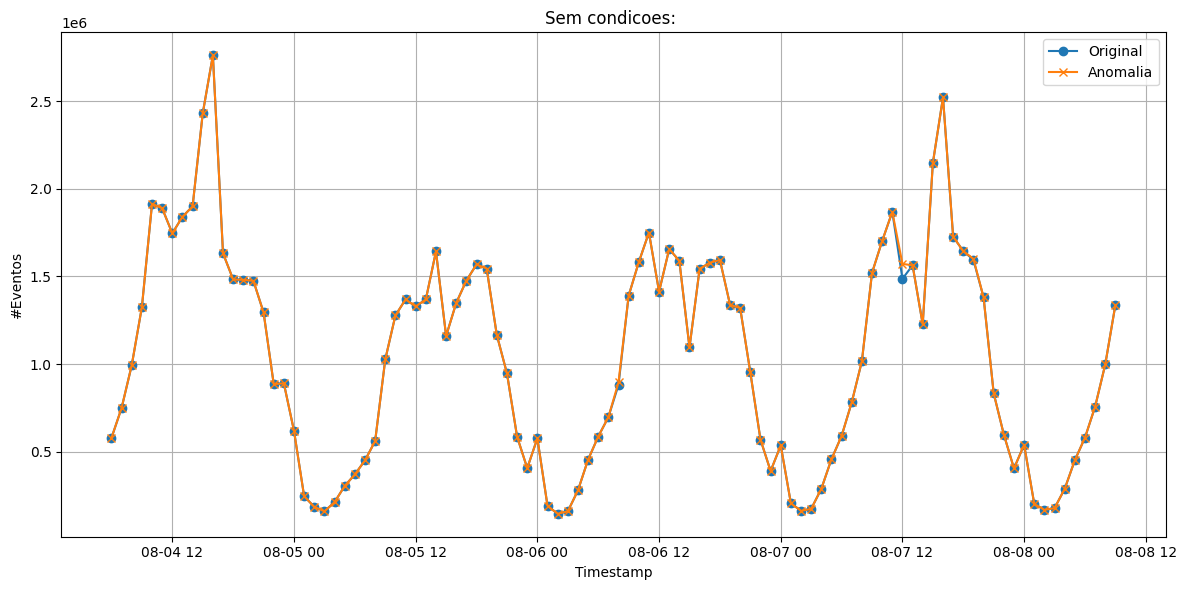

In [24]:
plot_figure(df_anomaly_agg, df_original_agg, center_ts, {}, "Sem condicoes")

In [25]:
conditions

{'Call Type': 'VOICE', 'Traffic Type': 'ON-NET', 'Service Type': 'ROAMING'}

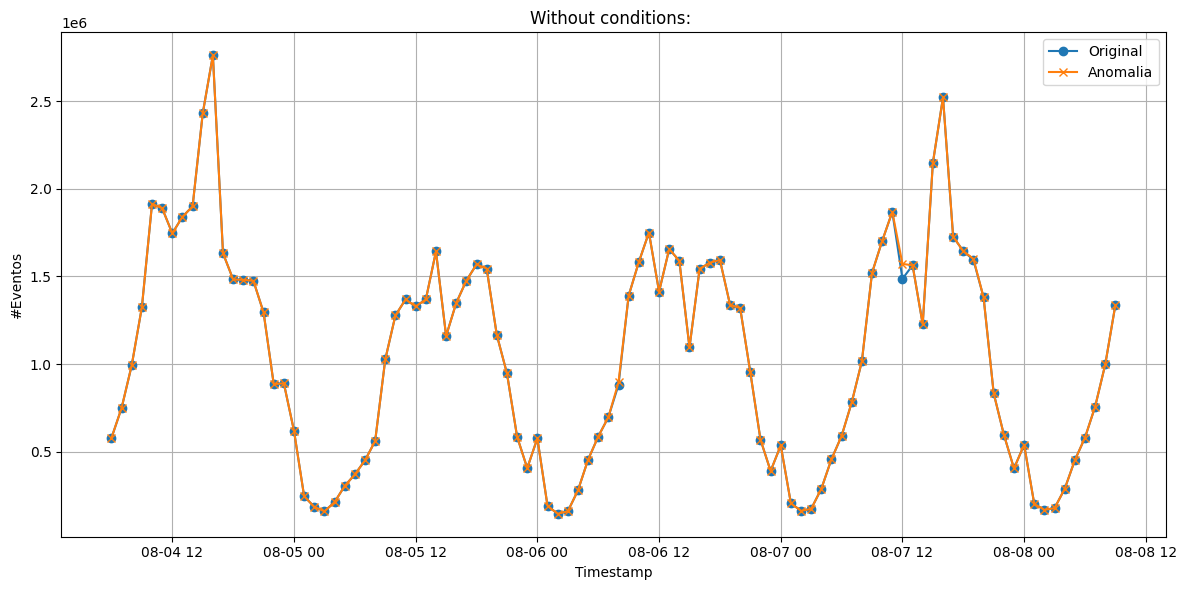

In [26]:
plot_figure(df_anomaly_agg, df_original_agg, center_ts, {}, "Without conditions")

In [27]:
available_categories = {
    'Call Type': df['Call Type'].unique().tolist(),
    'Event Type': df['Event Type'].unique().tolist(),
    'Subscriber Type': df['Subscriber Type'].unique().tolist(),
    'Traffic Type': df['Traffic Type'].unique().tolist(),
    'Service Type': df['Service Type'].unique().tolist(),
    'Partner Description': df['Partner Description'].unique().tolist(),
    'STOP': False
}


def revert_key_value_mapping(available_categories):
    reversed_mapping = {}
    for key, values in available_categories.items():
        if isinstance(values, list):  # Ensure the value is iterable
            for value in values:
                if value not in reversed_mapping:
                    reversed_mapping[value] = []
                reversed_mapping[value].append(key)
        else:
            # Handle non-list values (like the 'STOP' flag)
            value = values
            if value not in reversed_mapping:
                reversed_mapping[value] = []
            reversed_mapping[value].append(key)
    return reversed_mapping

In [28]:
rt_available_categories = revert_key_value_mapping(available_categories)

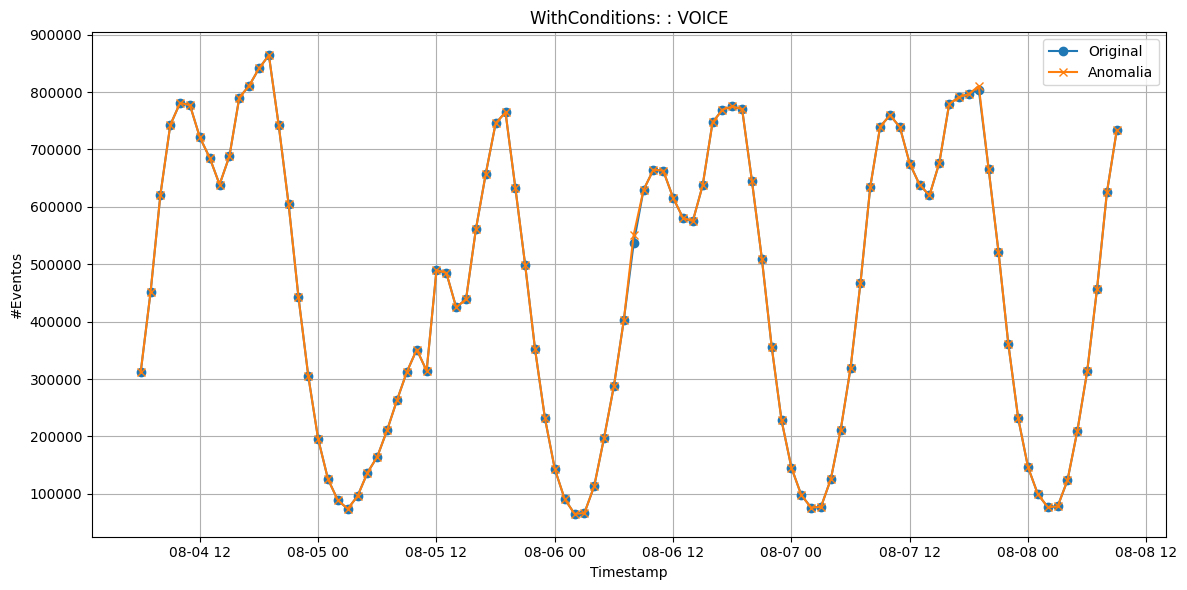

In [29]:
dictionary = {column:static_value}
df_original_cond = filter_and_aggregate(df, dictionary, False)
df_anomaly_cond = filter_and_aggregate(df_anomaly, dictionary, False)
plot_figure(df_anomaly_cond, df_original_cond, center_ts, dictionary, "WithConditions: ")

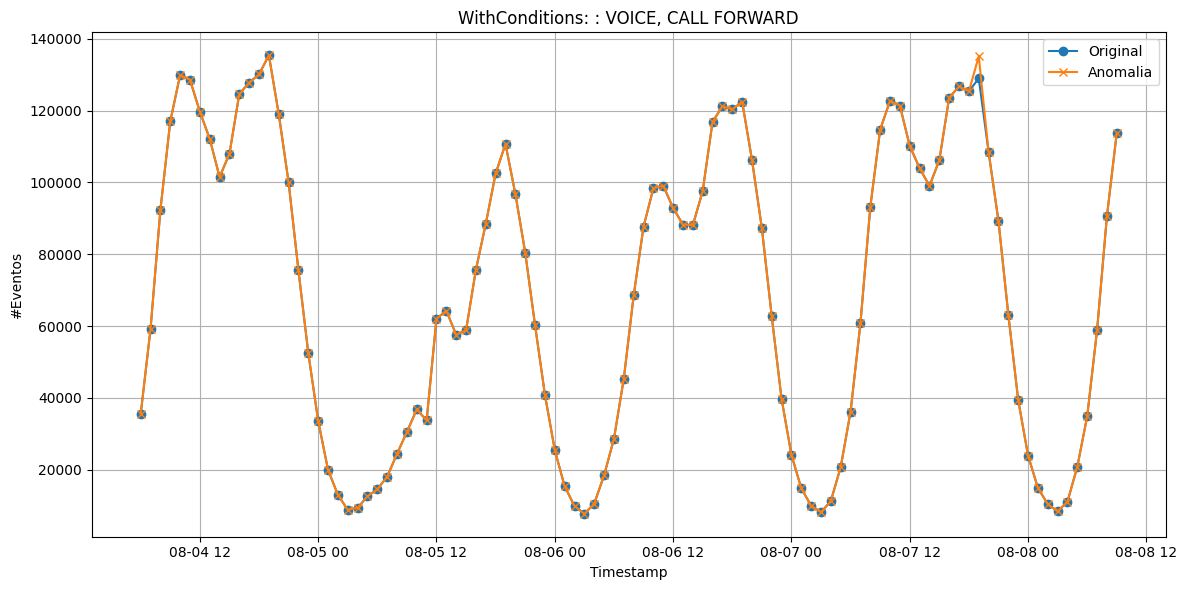

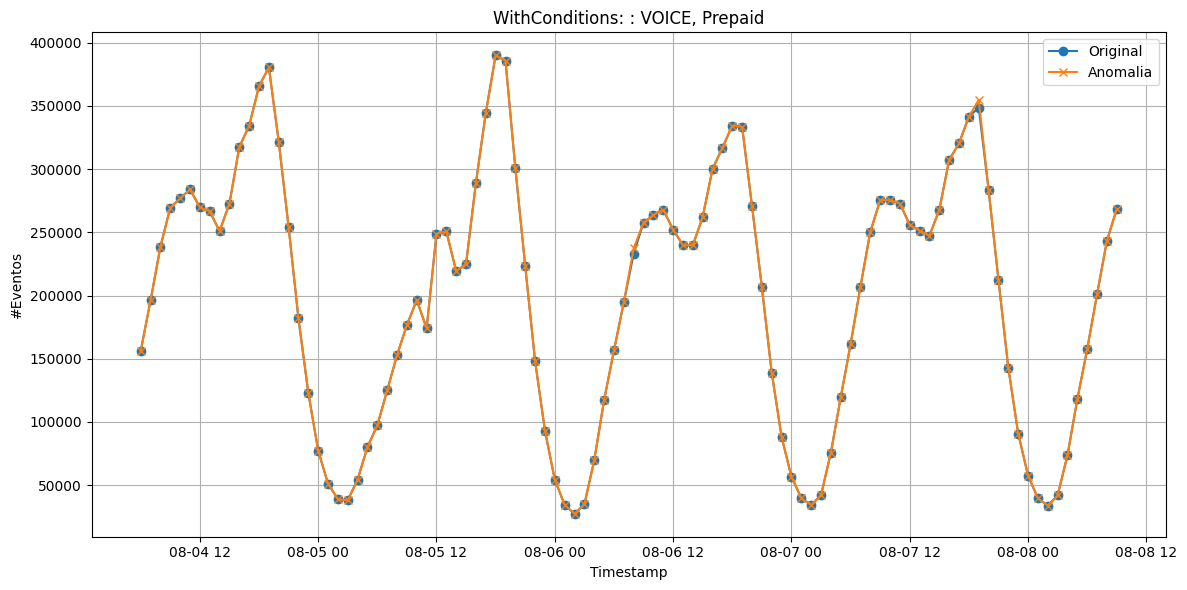

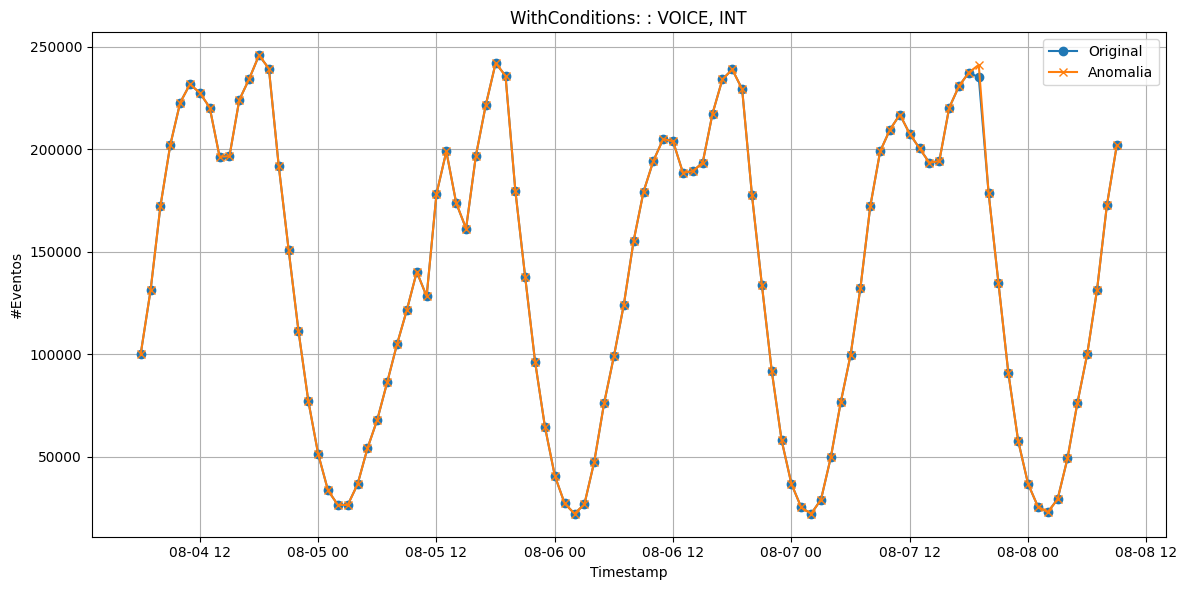

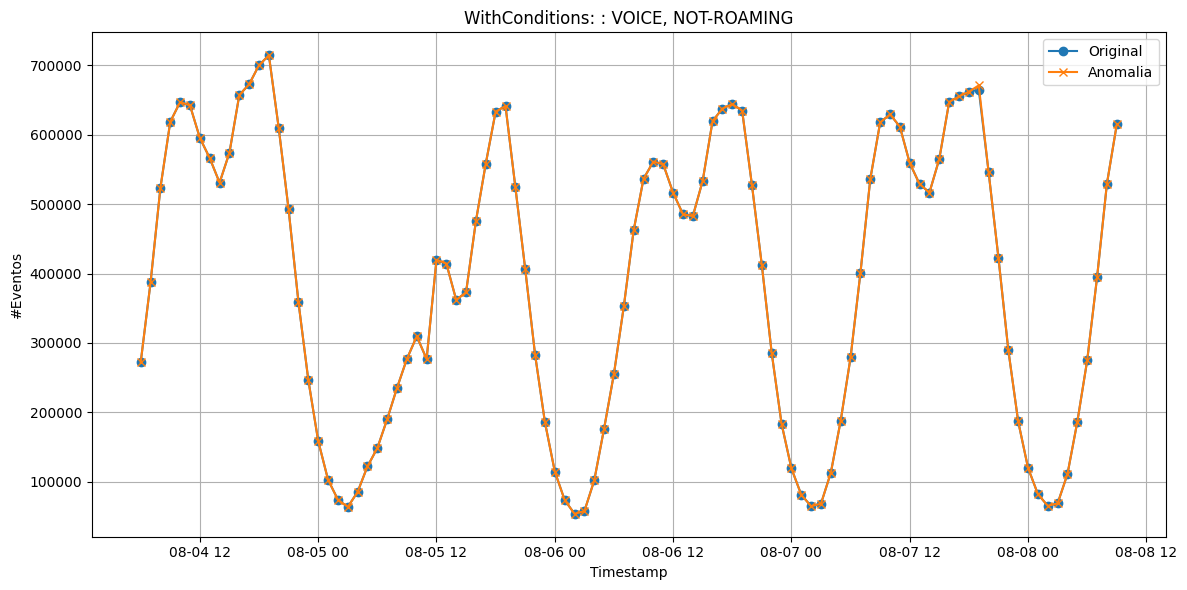

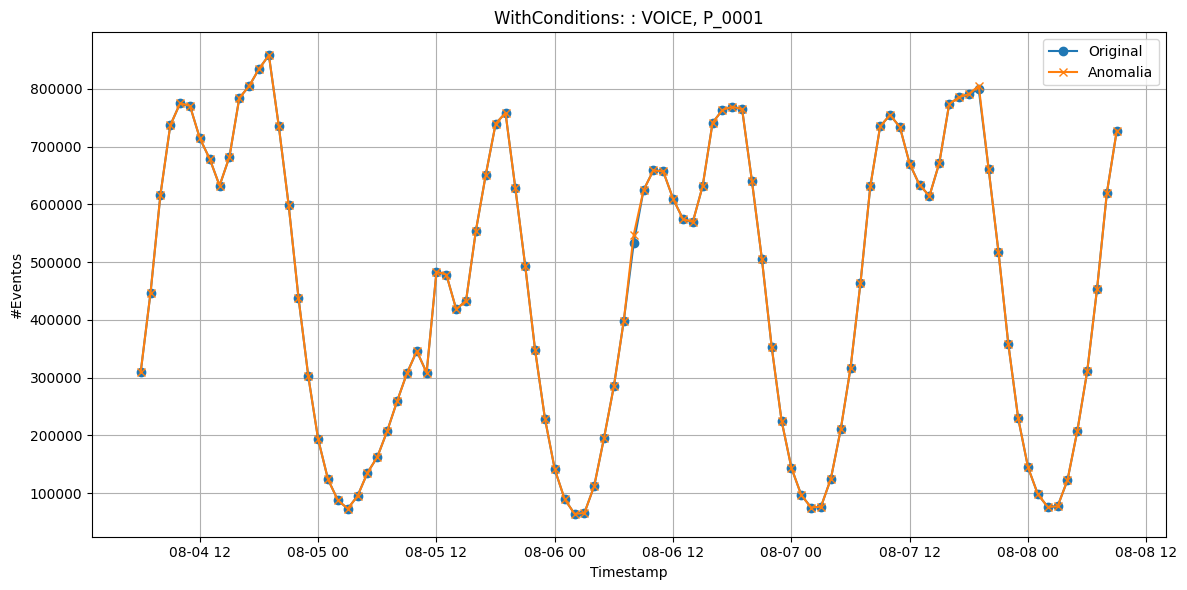

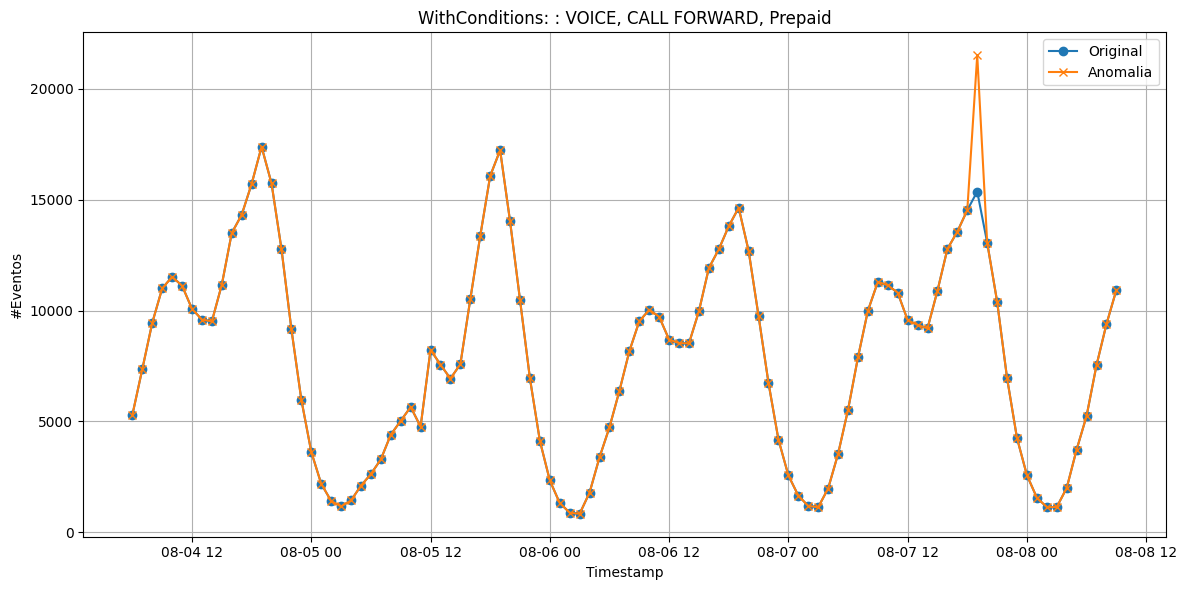

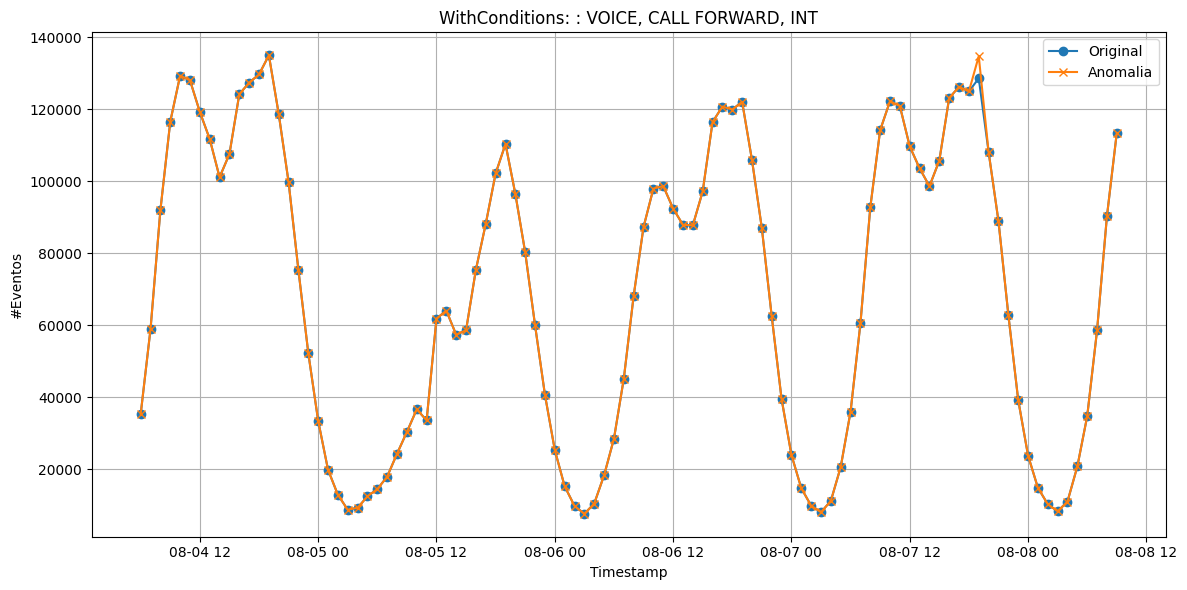

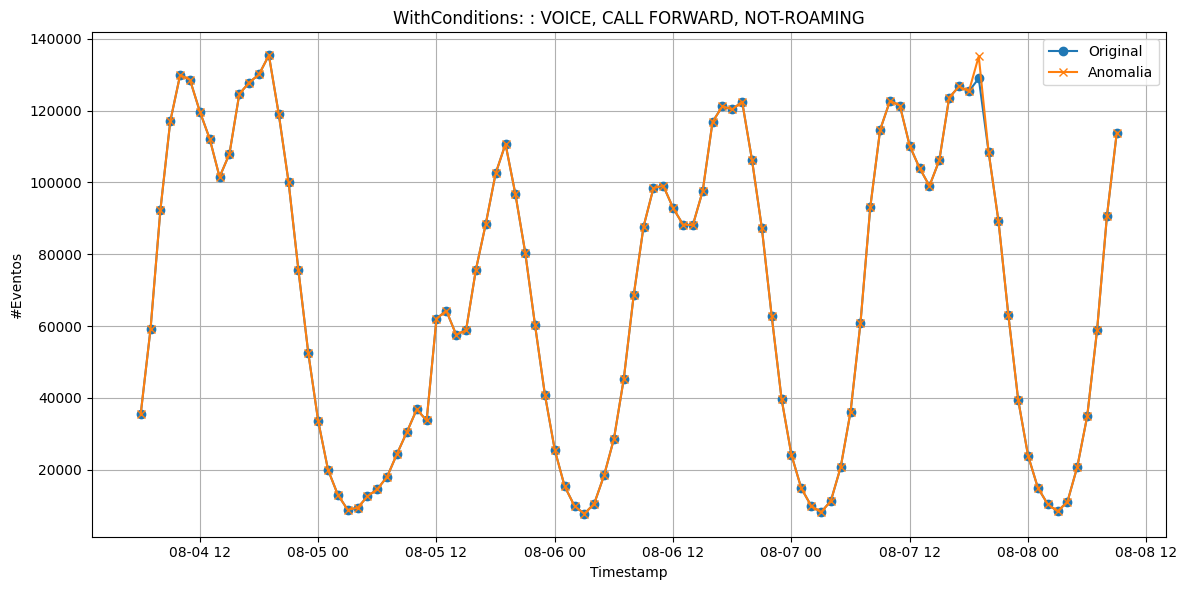

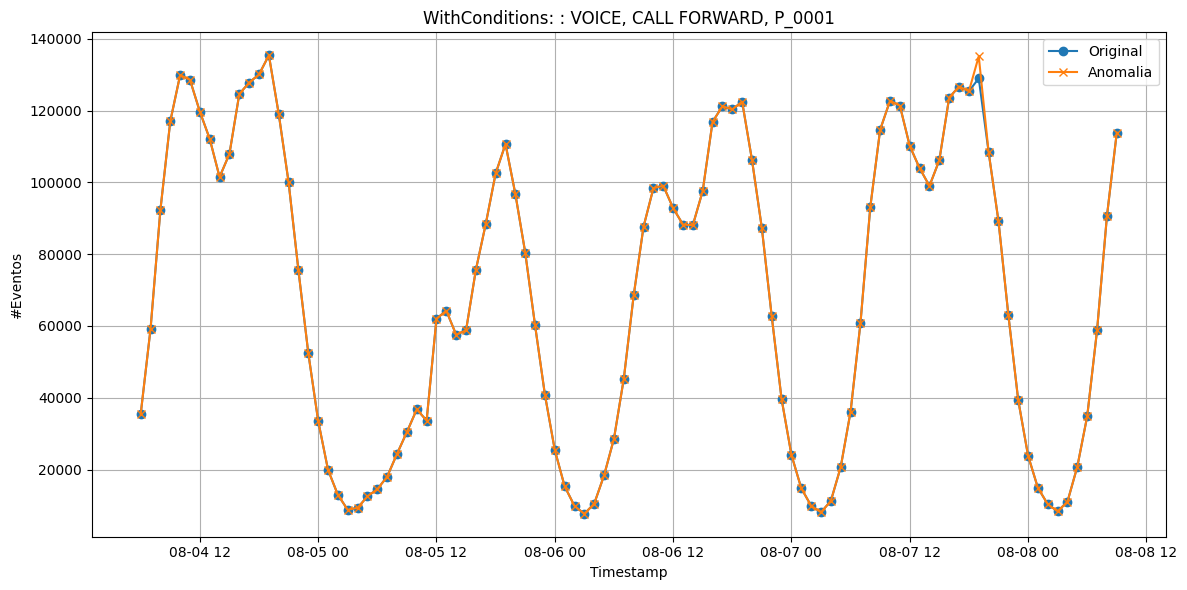

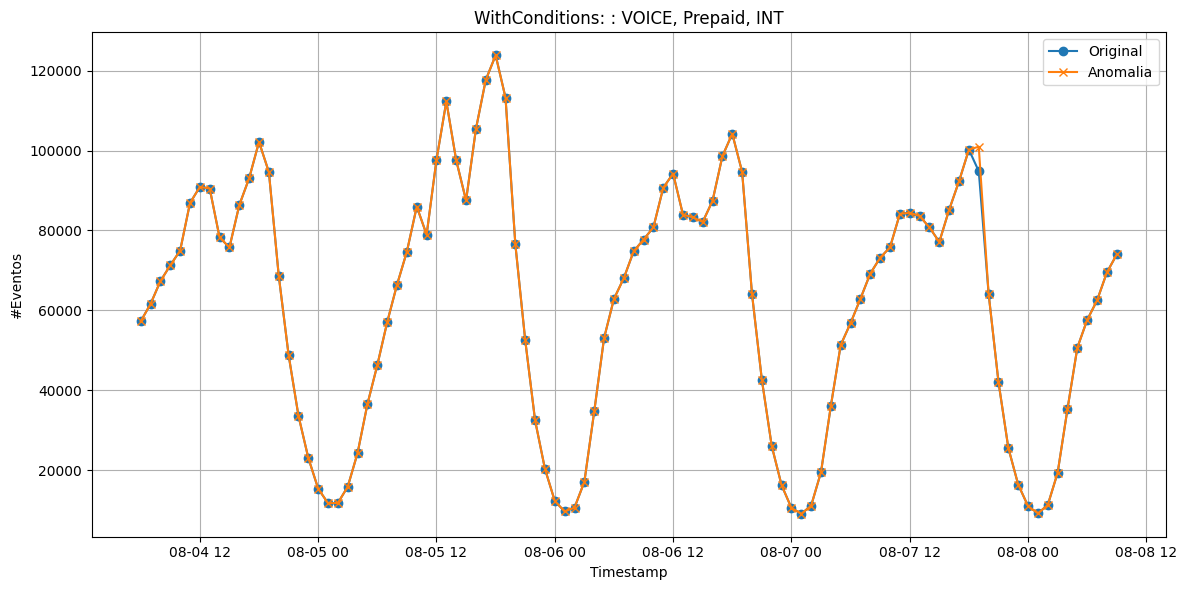

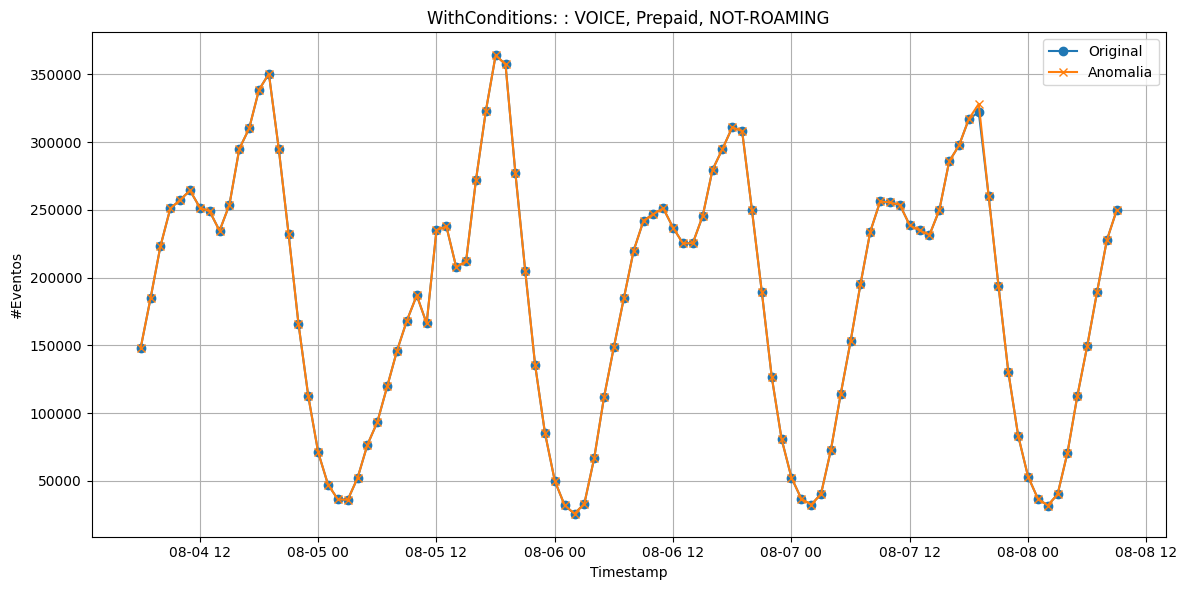

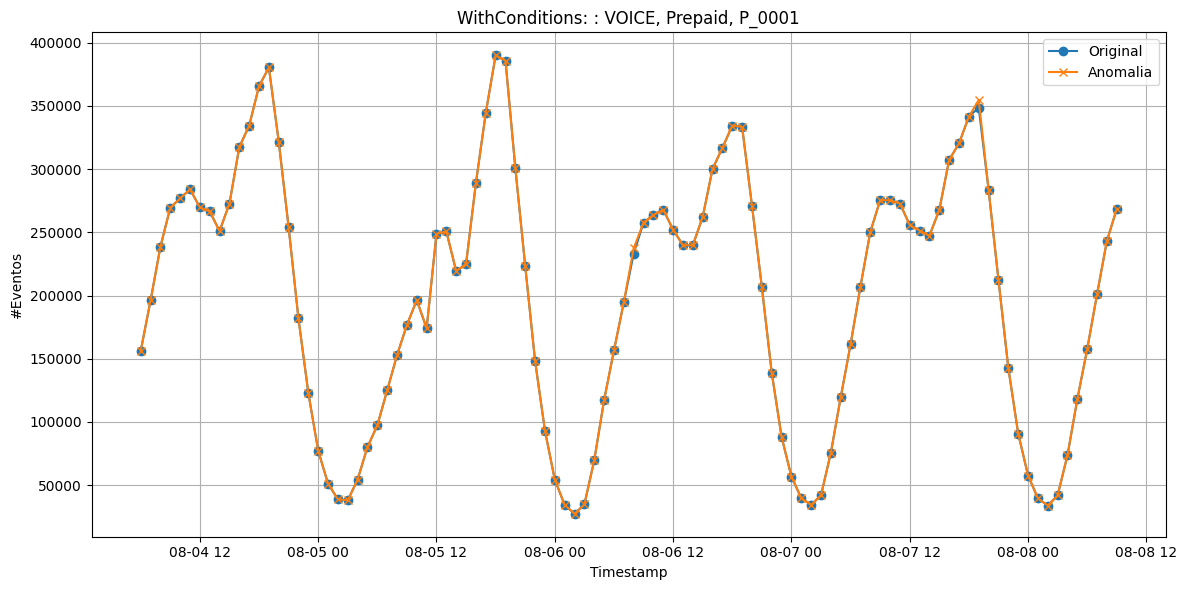

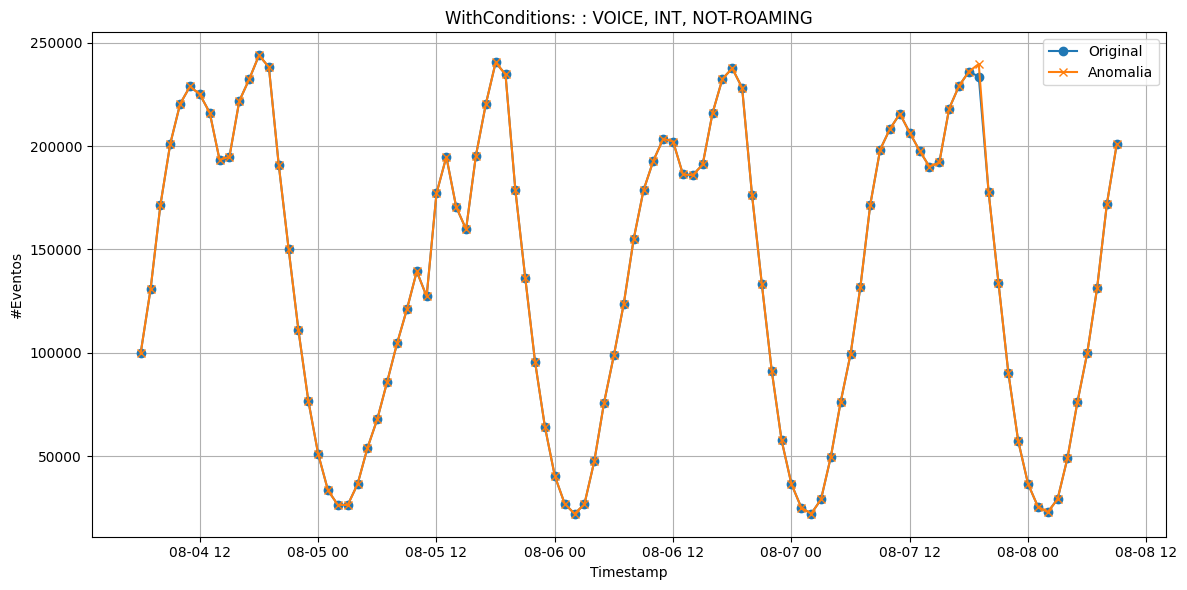

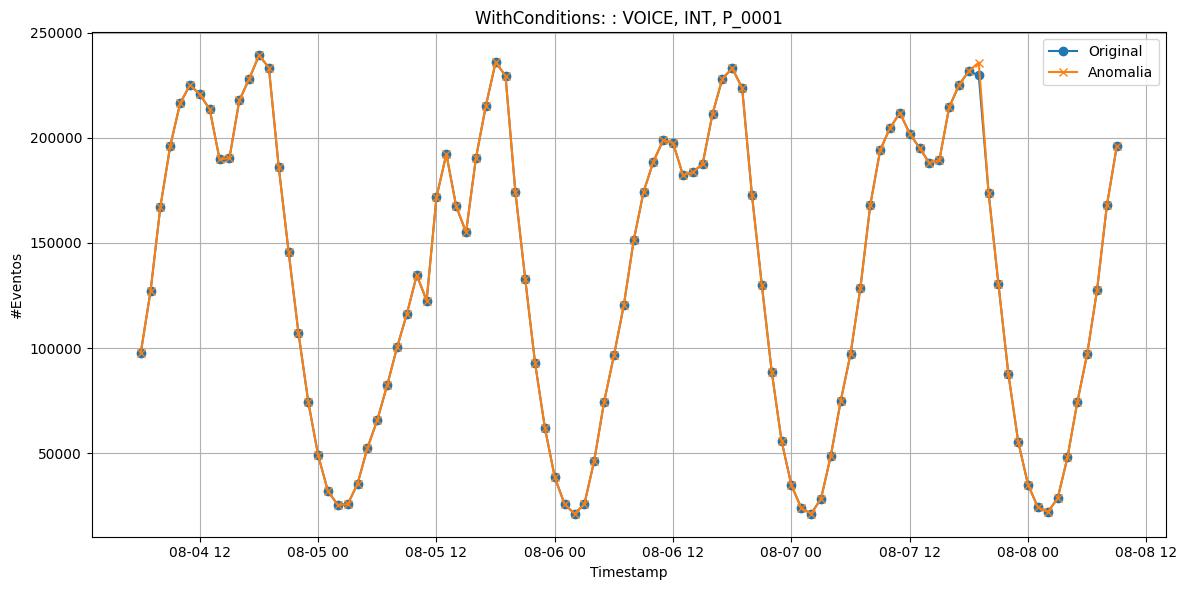

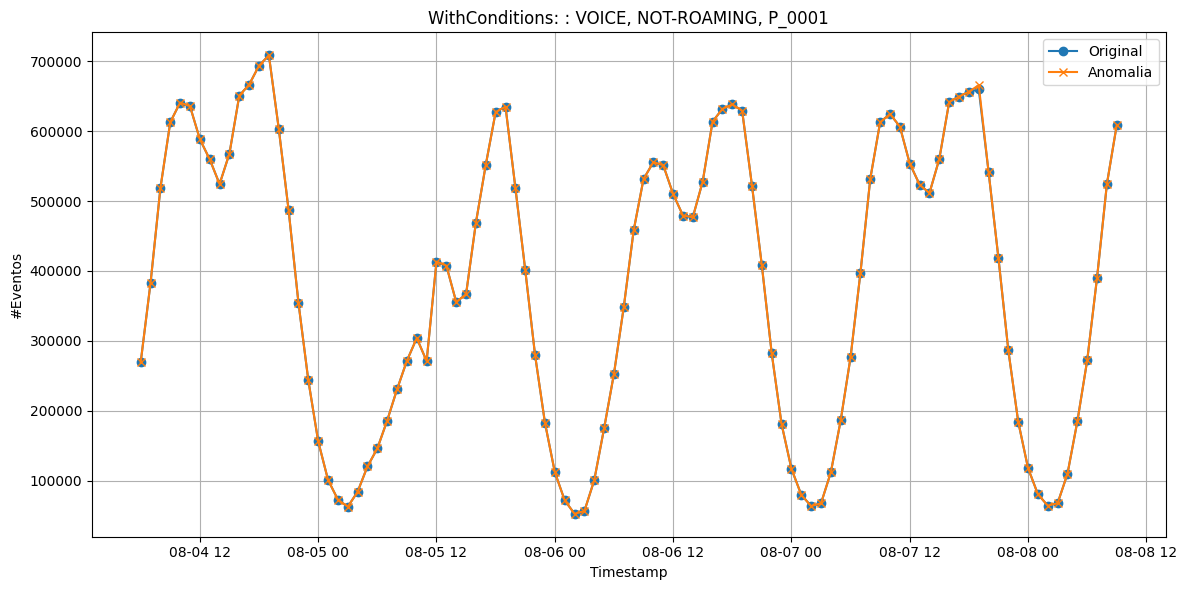

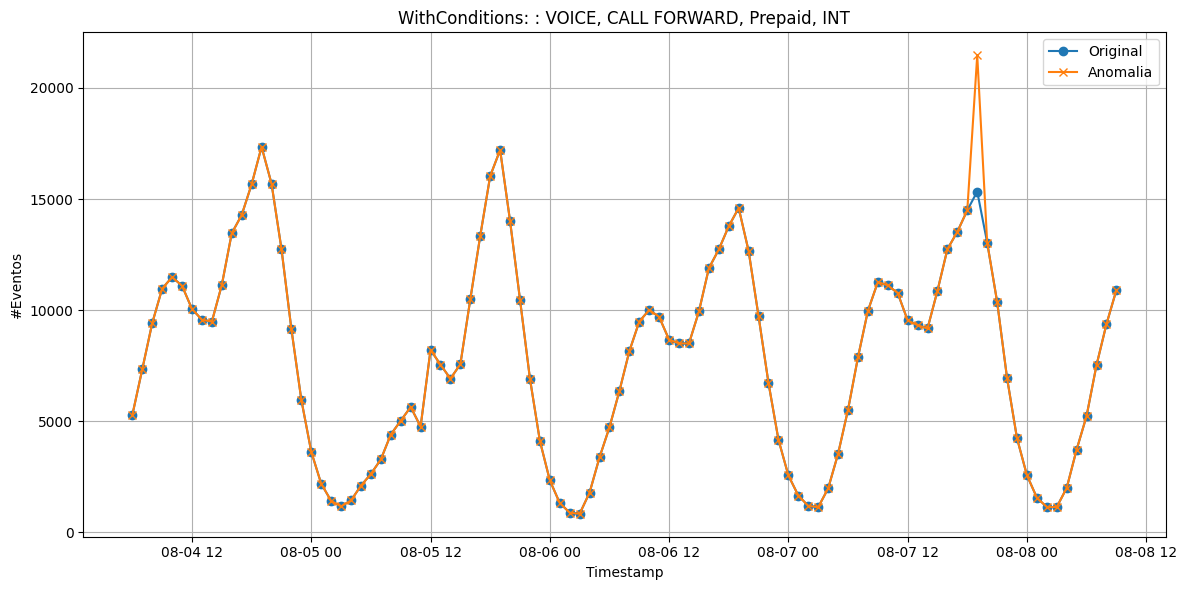

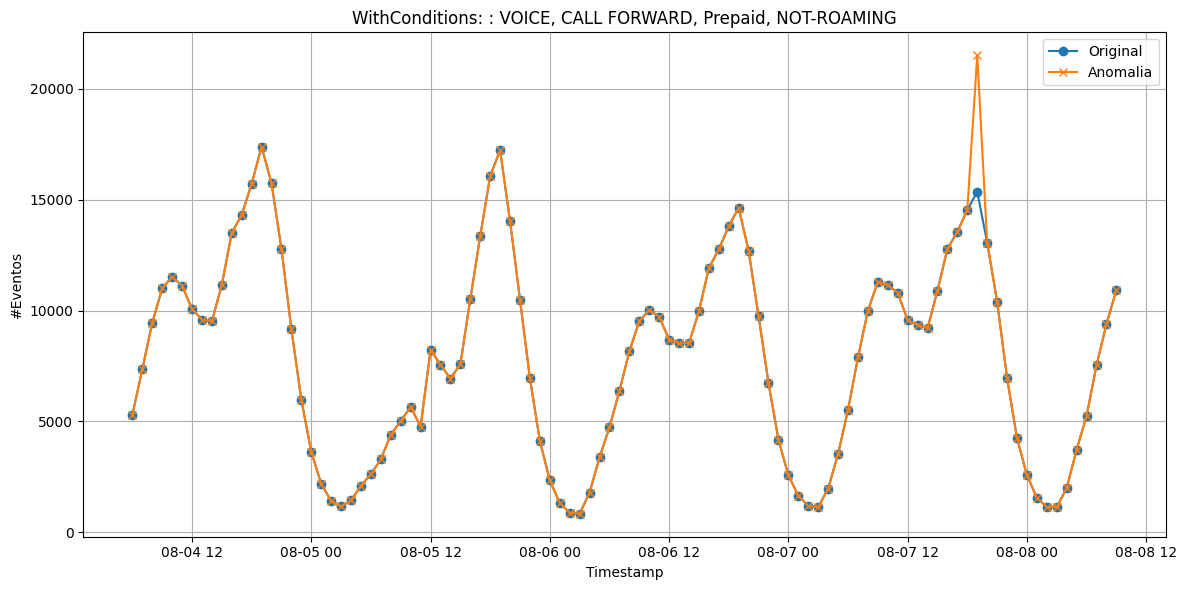

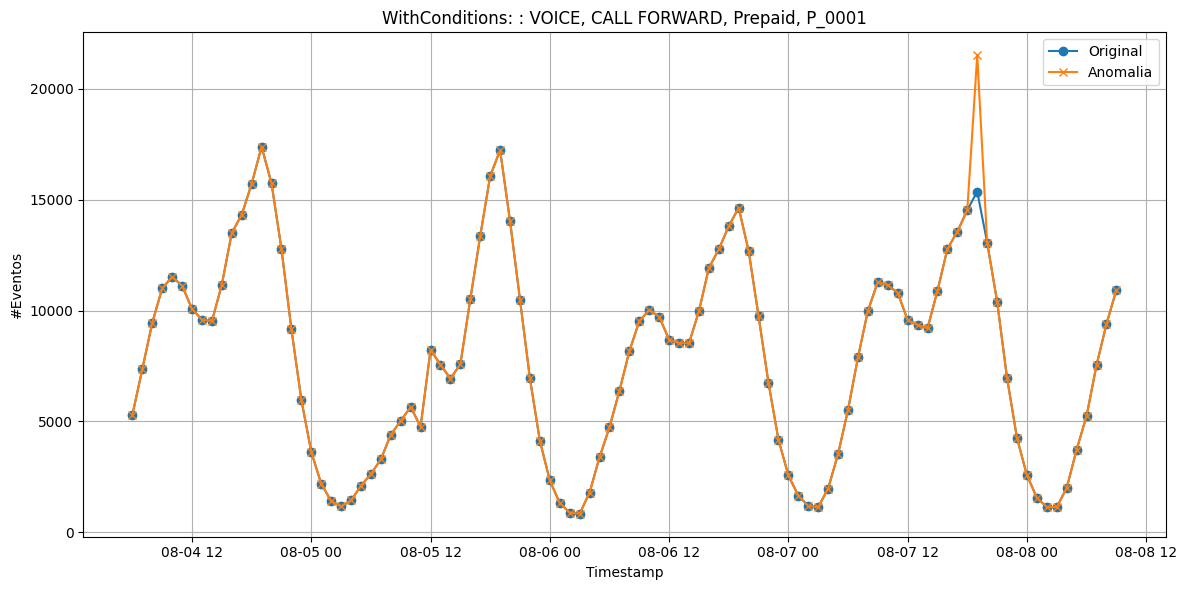

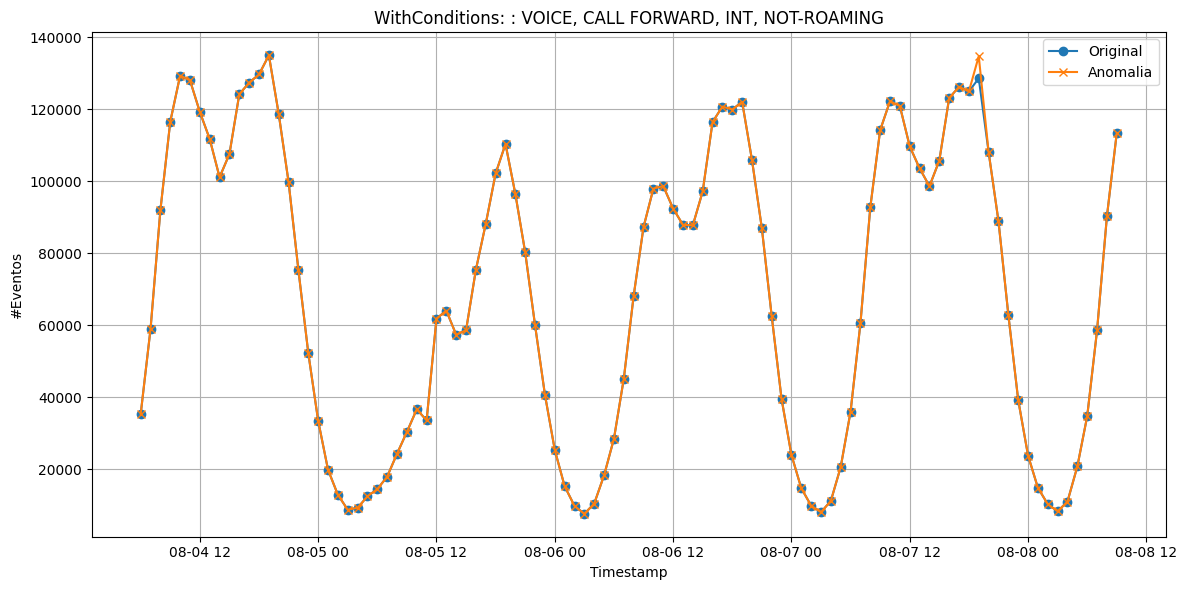

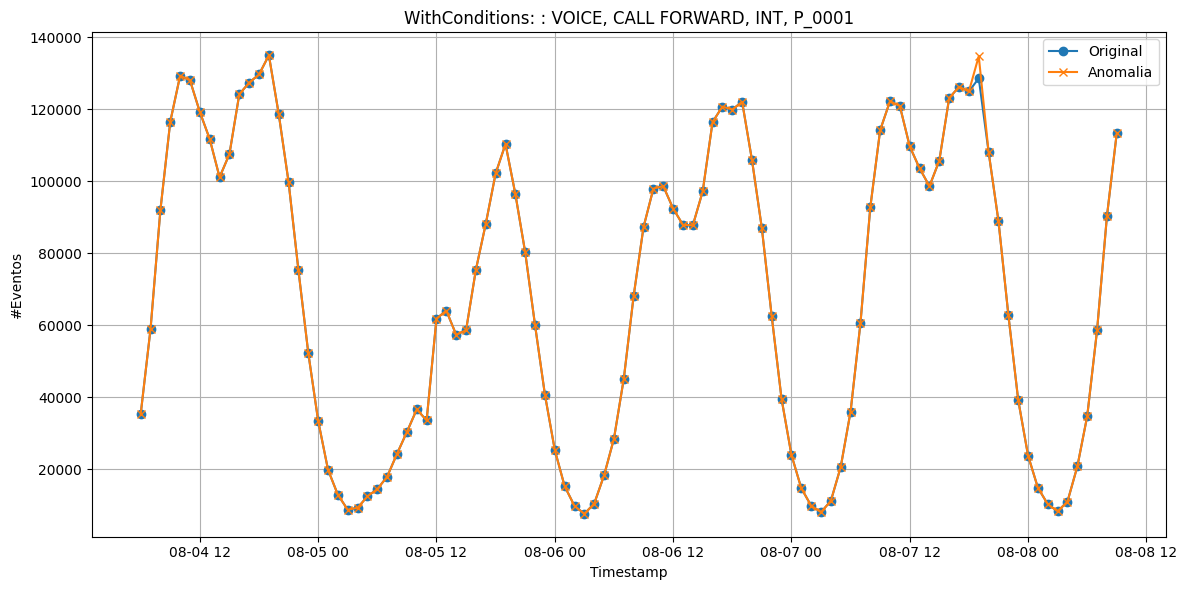

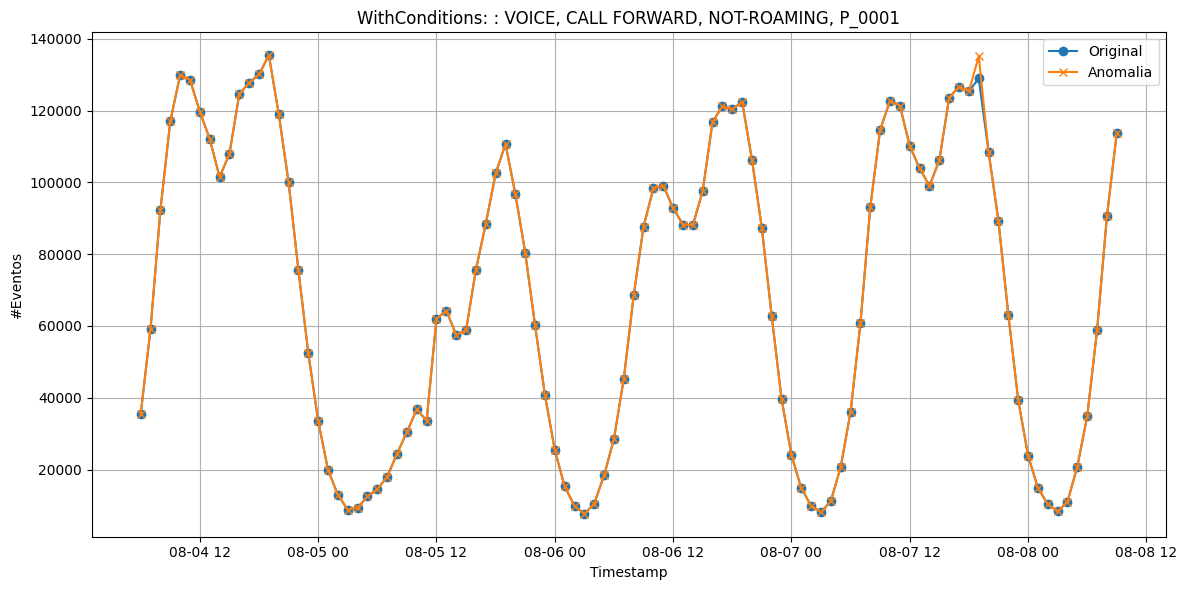

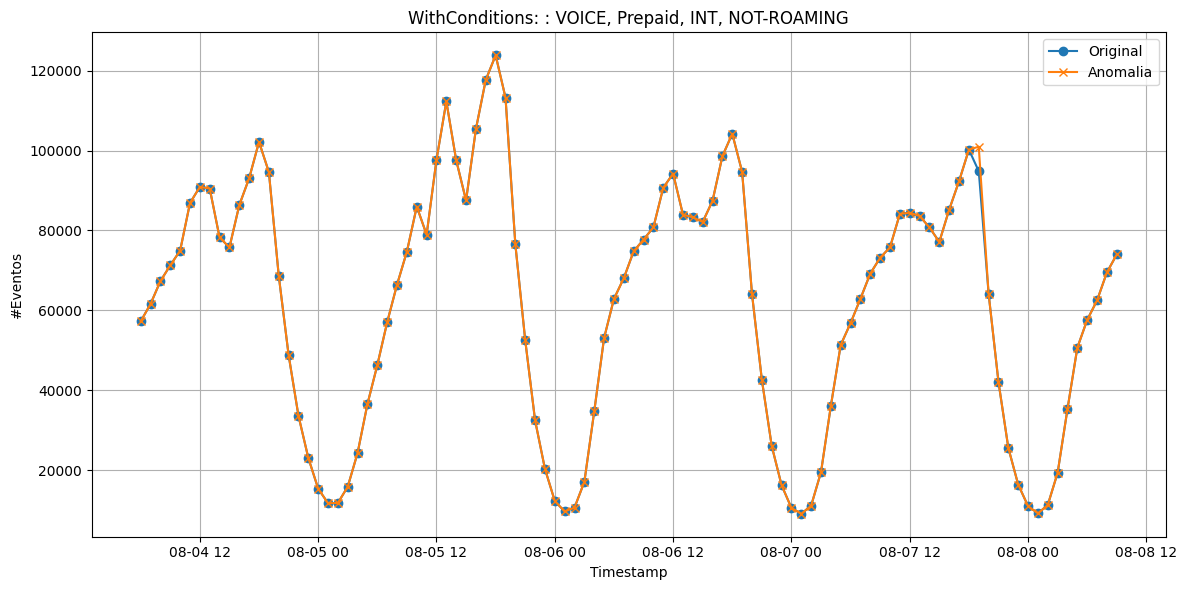

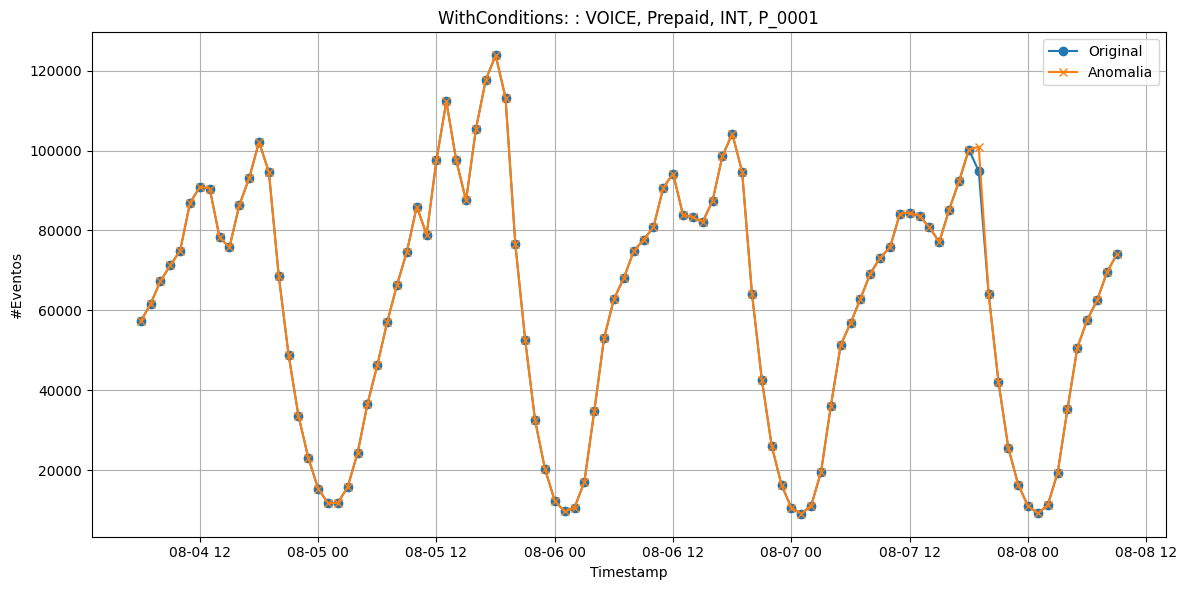

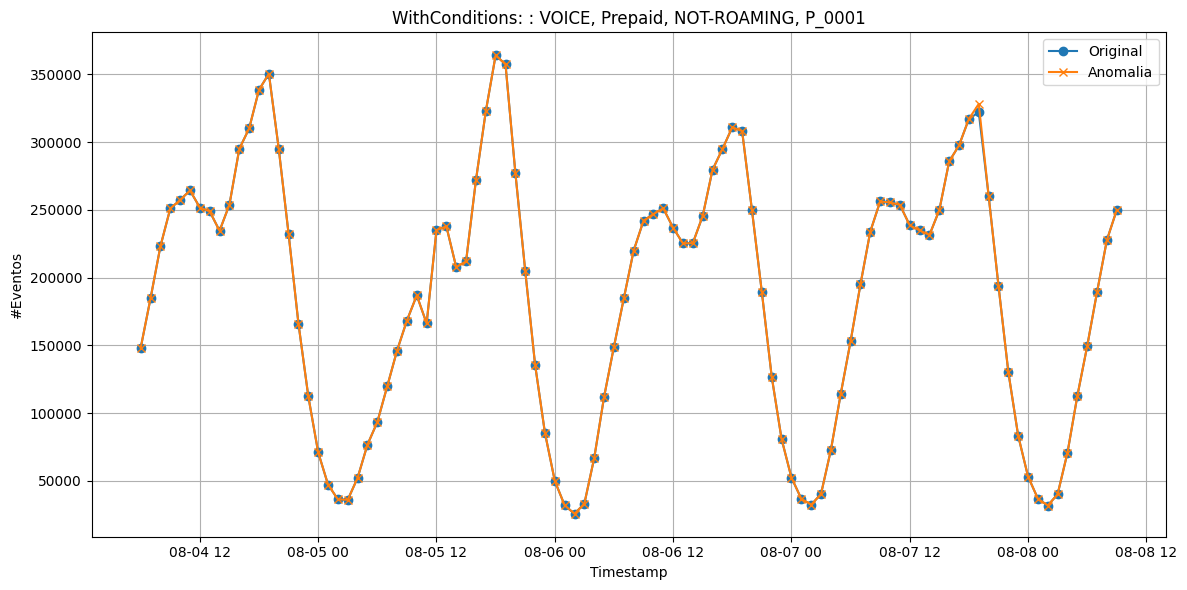

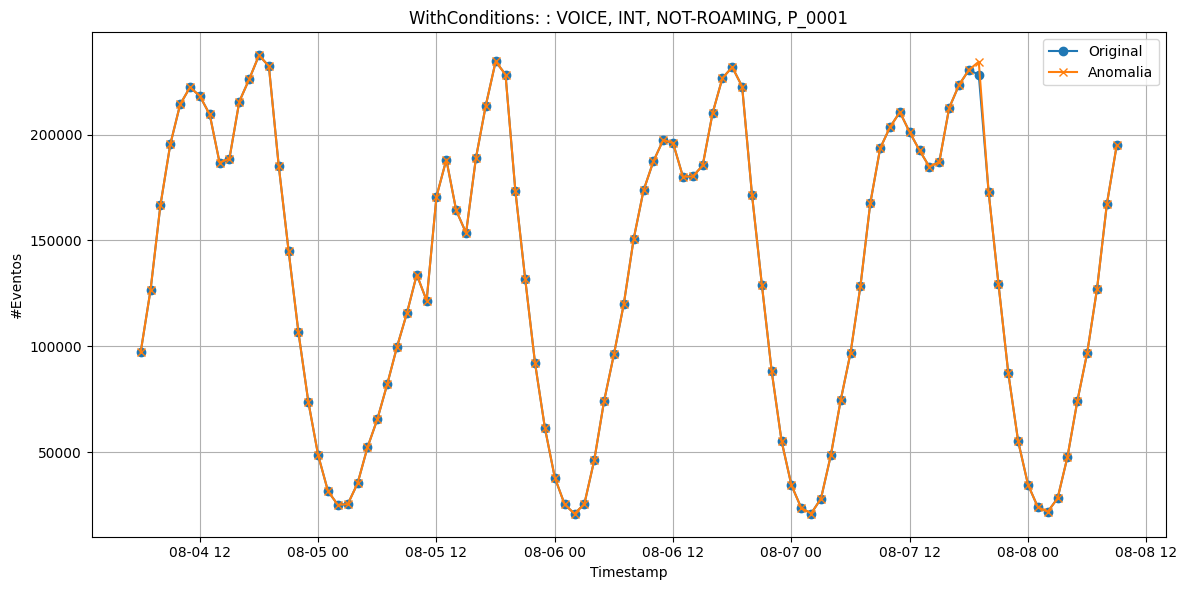

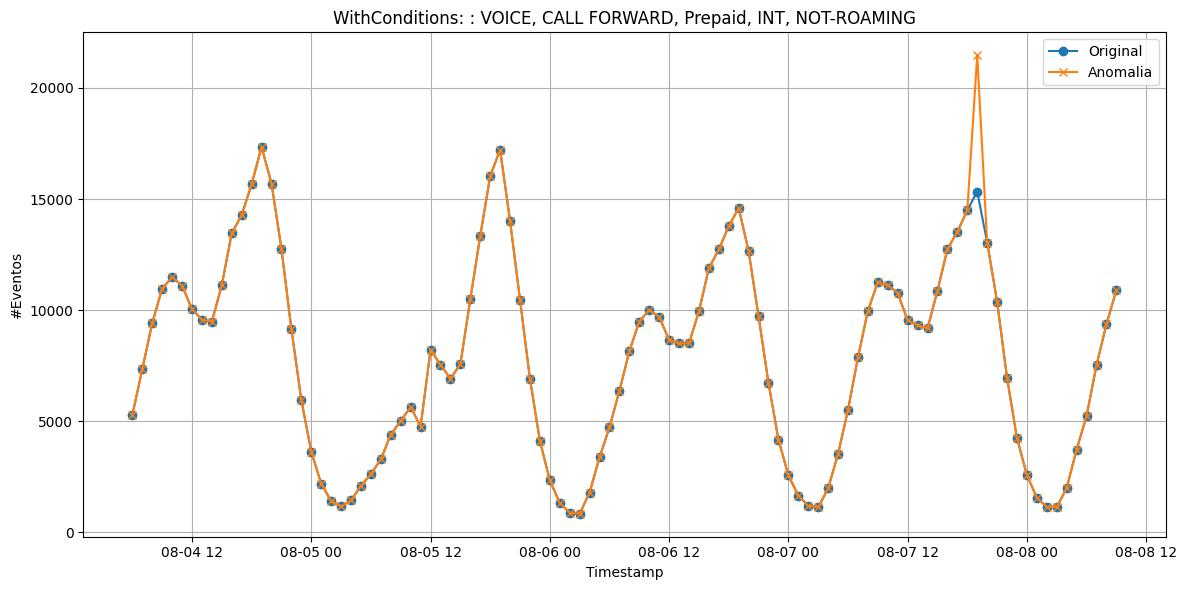

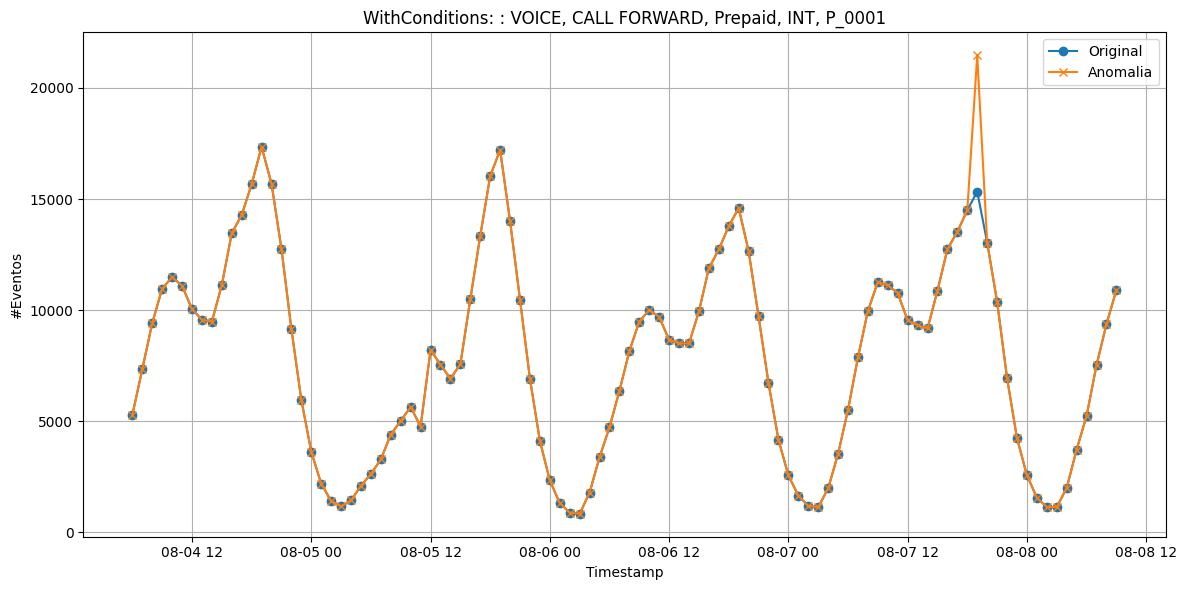

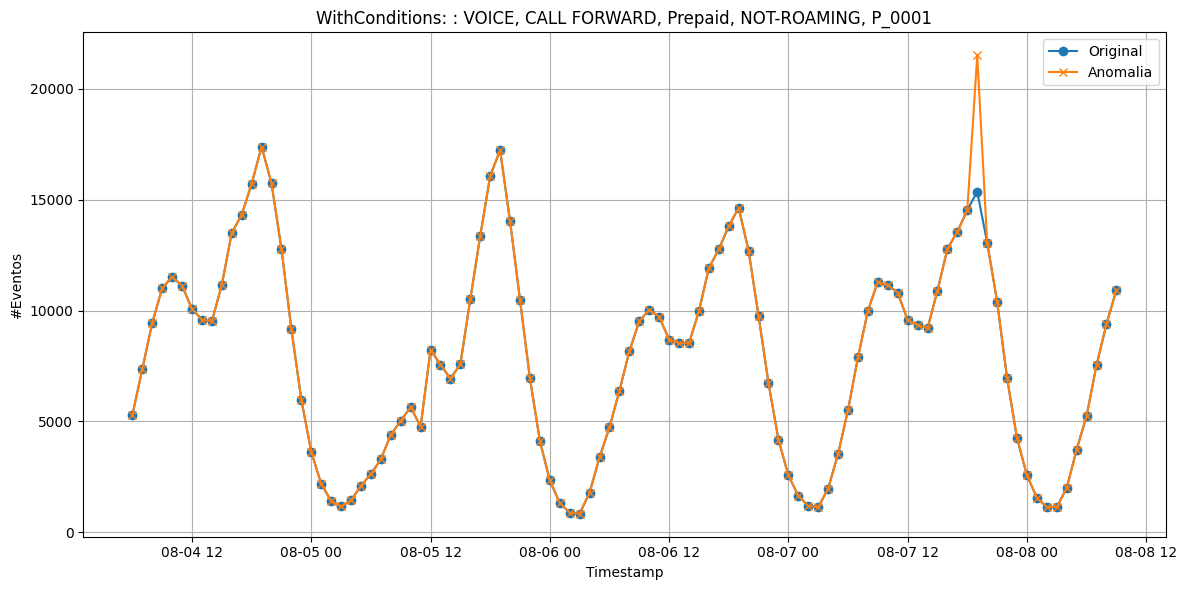

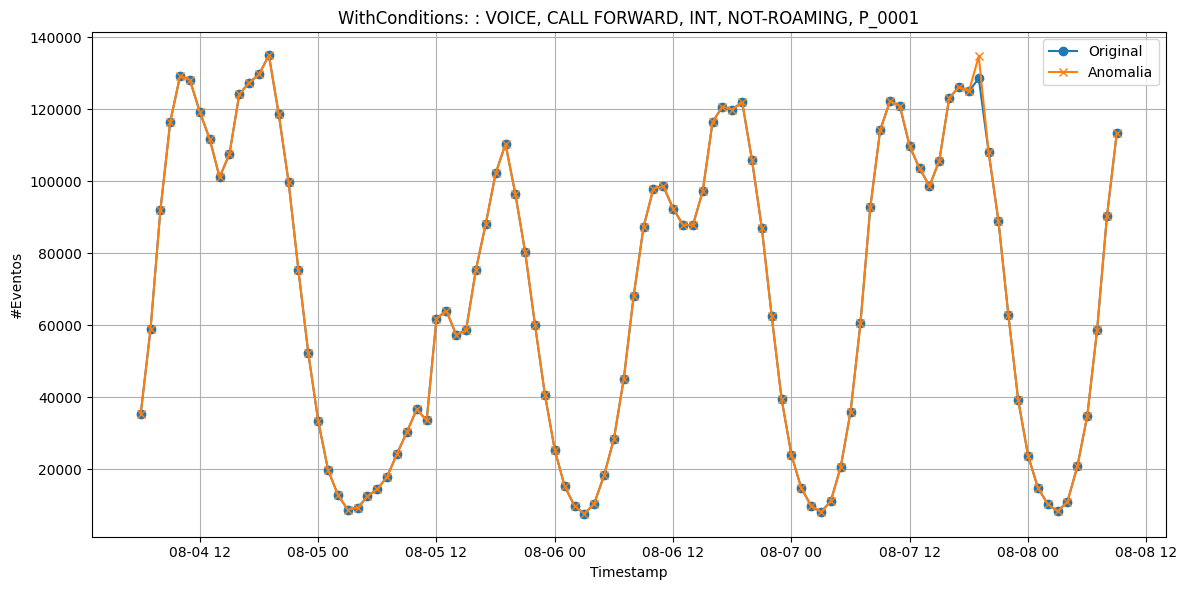

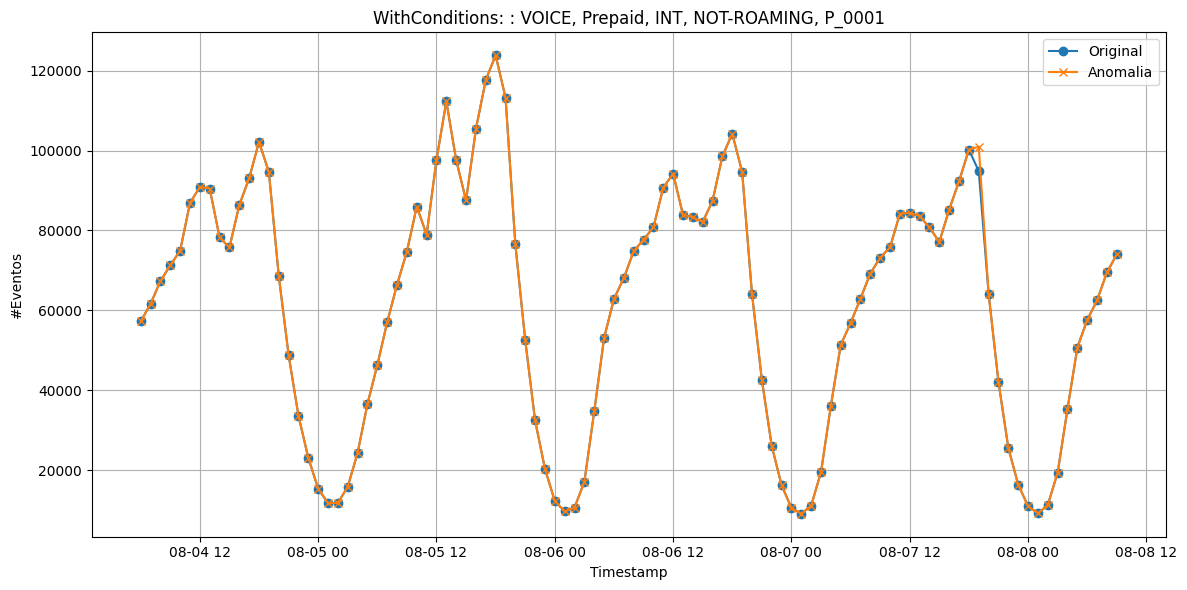

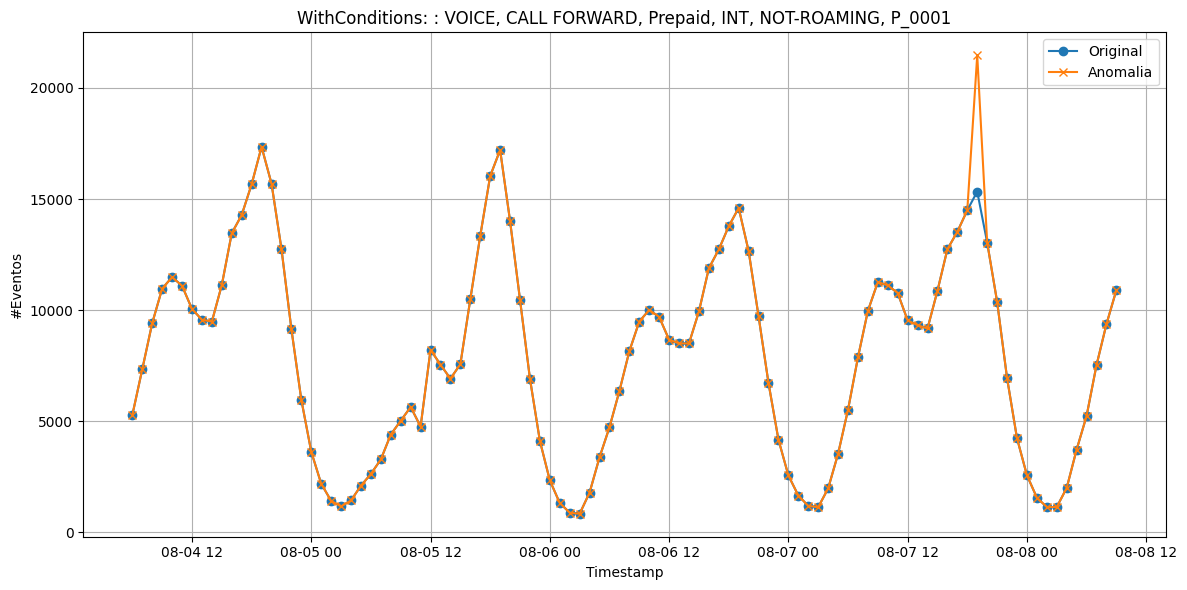

In [30]:
import itertools


def create_dictionaries(static_filter, filters, category_dict):
    all_combinations = []
    for r in range(1, len(filters) + 1):
        for combination in itertools.combinations(filters, r):
            current_dict = {}
            
            current_dict[static_filter[0]] = static_filter[1]
            for item in combination:
                category = category_dict.get(item)[0]
                
                if category:
                    # Assigning the filter to the correct category in the dictionary
                    
                    current_dict[category] = item
            if current_dict:  # Make sure the dictionary is not empty
                all_combinations.append(current_dict)
    return all_combinations

# Generating dictionaries
static_filter = [column, static_value]
resulting_dictionaries = create_dictionaries(static_filter, plot_filters, rt_available_categories)


# Print each generated dictionary
for dictionary in resulting_dictionaries:
    df_original_cond = filter_and_aggregate(df, dictionary, False)
    df_anomaly_cond = filter_and_aggregate(df_anomaly, dictionary, False)
    plot_figure(df_anomaly_cond, df_original_cond, center_ts, dictionary, "WithConditions: ")